# Challenge 2: Online Purchase Prediction (Final Notebook)

**CAI 4105, Fall 2026, Team 4:** Dariya, Rimma, Bakai, Niyaz

**Goal:** predict whether an online shopping session ends with a purchase (`Revenue=True`).

This notebook contains the complete workflow, from loading the data to writing `predictions.csv`.
It brings the team's individual notebooks together and runs every model under one shared validation protocol.

| Section | Content | Developed in |
|---|---|---|
| 1-3 | Data checks, preprocessing, validation strategy | `01_data_preprocessing.ipynb` (Dariya) |
| 4-5 | Logistic Regression, Naive Bayes, KNN, SVM: baselines and Grid Search | `02_models_1-4.ipynb` (Rimma) |
| 4-5 | Decision Tree, Random Forest, Gradient Boosting: baselines and Grid Search | `03_bakai_models.ipynb` (Bakai) |
| 6 | Comparison of all seven required models | this notebook |
| 7-9 | Final model selection, confusion matrix, final training, `predictions.csv` | this notebook (Niyaz) |

The primary metric is **F1 for the positive class (`Revenue=True`)**.
The test file is read only in Section 9, to generate the final predictions.

Run the notebook from the `challenge2` folder with `challenge2_train.csv` and `challenge2_test.csv` next to it.

In [1]:
import sys
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay, accuracy_score, classification_report,
    confusion_matrix, f1_score, make_scorer, precision_score, recall_score,
)
from sklearn.model_selection import (
    GridSearchCV, StratifiedGroupKFold, cross_val_predict, cross_validate,
)
from sklearn.naive_bayes import BernoulliNB, GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    KBinsDiscretizer, OneHotEncoder, PowerTransformer, StandardScaler,
)
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

RANDOM_STATE = 42

# Known warnings that do not affect the results and would otherwise fill the output:
# - KBinsDiscretizer merges quantile bins with identical edges (several features are 0 in most sessions);
# - the `penalty` argument of LogisticRegression is deprecated since scikit-learn 1.8 (it still works in 1.9);
# - joblib reports when it restarts one of its parallel worker processes.
warnings.filterwarnings("ignore", message="Bins whose width are too small")
warnings.filterwarnings("ignore", message=".*penalty.*deprecated")
warnings.filterwarnings("ignore", message="A worker stopped while some jobs were given to the executor")

print("Python", sys.version.split()[0])
print("pandas", pd.__version__, "| scikit-learn", sklearn.__version__, "| numpy", np.__version__)

Python 3.14.6
pandas 3.0.3 | scikit-learn 1.9.0 | numpy 2.4.6


## 1. Load and explore the data

### 1.1 Data checks

In [2]:
train_df = pd.read_csv("challenge2_train.csv")
print("Training data shape:", train_df.shape)
train_df.head()

Training data shape: (9247, 19)


,ID,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,1,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,3,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
2,4,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
3,7,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.4,Feb,2,4,3,3,Returning_Visitor,False,False
4,9,0,0.0,0,0.0,2,37.000000,0.00,0.10,0.0,0.8,Feb,2,2,2,3,Returning_Visitor,False,False


In [3]:
print("Total missing values:", train_df.isna().sum().sum())
print("Duplicate IDs:", train_df["ID"].duplicated().sum())

revenue_summary = train_df["Revenue"].value_counts(dropna=False).to_frame("Count")
revenue_summary["Percent"] = (
    revenue_summary["Count"] / len(train_df) * 100
).round(2)

display(revenue_summary)

Total missing values: 0
Duplicate IDs: 0


,Count,Percent
Revenue,,
False,7816,84.52
True,1431,15.48


The training data has 9,247 sessions, no missing values and no duplicate IDs.

**The target is imbalanced:** only 15.48% of sessions end with a purchase. A model that always predicts
"no purchase" would be 84.52% accurate and would not find a single buyer (F1 = 0). This is why accuracy is
not used to compare models and F1 for `Revenue=True` is the primary metric.

### 1.2 Target and predictors

`Revenue` is the target. `ID` only identifies a session, so it is excluded from the predictors.

`OperatingSystems`, `Browser`, `Region` and `TrafficType` are stored as integers, but the numbers are codes
without any order, so we treat them as categorical together with `Month`, `VisitorType` and `Weekend`.

In [4]:
X = train_df.drop(columns=["ID", "Revenue"])
y = train_df["Revenue"]

categorical_features = [
    "Month", "OperatingSystems", "Browser", "Region",
    "TrafficType", "VisitorType", "Weekend",
]
numeric_features = X.columns.difference(
    categorical_features, sort=False
).tolist()

print("Feature matrix:", X.shape)
print("Numeric features:", len(numeric_features))
print("Categorical features:", len(categorical_features))

Feature matrix: (9247, 17)
Numeric features: 10
Categorical features: 7


### 1.3 Exploration

In [5]:
numeric_summary = X[numeric_features].describe().T[["mean", "50%", "max"]]
numeric_summary["skew"] = X[numeric_features].skew()
numeric_summary["zero (%)"] = (X[numeric_features] == 0).mean() * 100
display(numeric_summary.round(2))

print("Correlation of BounceRates and ExitRates:",
      round(X["BounceRates"].corr(X["ExitRates"]), 3))

,mean,50%,max,skew,zero (%)
Administrative,2.31,1.00,27.00,1.99,46.67
Administrative_Duration,81.17,8.00,3398.75,5.72,47.65
Informational,0.50,0.00,24.00,4.19,78.64
Informational_Duration,34.52,0.00,2549.38,7.80,80.55
ProductRelated,31.36,18.00,705.00,4.40,0.28
ProductRelated_Duration,1181.85,598.25,63973.52,8.23,6.17
BounceRates,0.02,0.00,0.20,2.93,45.06
ExitRates,0.04,0.03,0.20,2.13,0.64
PageValues,5.98,0.00,361.76,6.25,77.74
SpecialDay,0.06,0.00,1.00,3.24,89.60


Correlation of BounceRates and ExitRates: 0.912


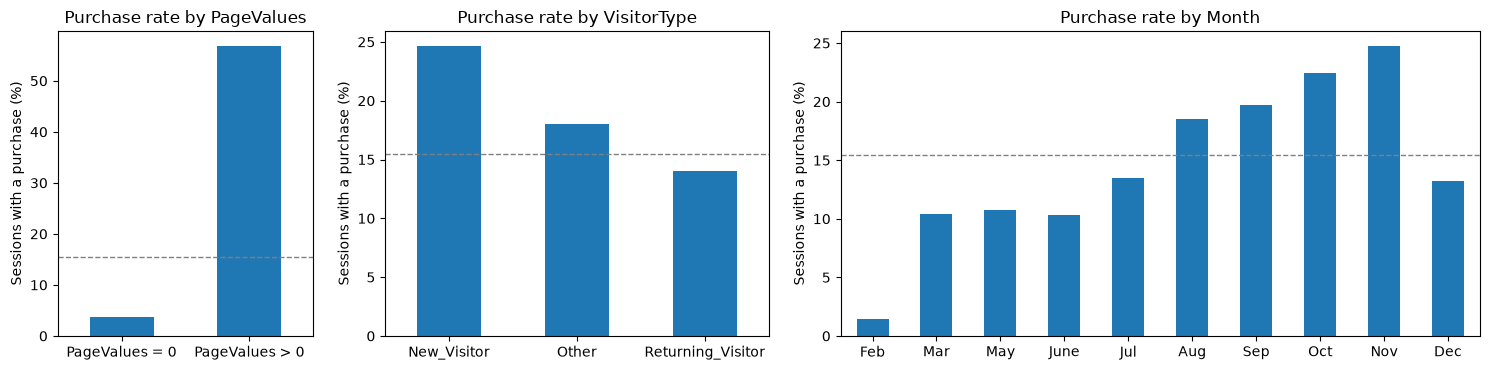

Dashed line: overall purchase rate (15.48%)


,Sessions,Purchase rate (%)
PageValues,,
PageValues = 0,7189,3.63
PageValues > 0,2058,56.85


In [6]:
def purchase_rate(key):
    return y.groupby(key).mean() * 100

page_values = (X["PageValues"] > 0).map({False: "PageValues = 0", True: "PageValues > 0"})
month_order = ["Feb", "Mar", "May", "June", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

panels = [
    ("PageValues", purchase_rate(page_values)),
    ("VisitorType", purchase_rate(X["VisitorType"])),
    ("Month", purchase_rate(X["Month"]).reindex(month_order)),
]

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), gridspec_kw={"width_ratios": [2, 3, 5]})
for ax, (title, rates) in zip(axes, panels):
    rates.plot.bar(ax=ax, rot=0, color="tab:blue")
    ax.axhline(100 * y.mean(), color="gray", linestyle="--", linewidth=1)
    ax.set_title(f"Purchase rate by {title}")
    ax.set_xlabel("")
    ax.set_ylabel("Sessions with a purchase (%)")
plt.tight_layout()
plt.show()

print("Dashed line: overall purchase rate (%.2f%%)" % (100 * y.mean()))
display(pd.DataFrame({
    "Sessions": page_values.value_counts(),
    "Purchase rate (%)": purchase_rate(page_values).round(2),
}))

In [7]:
shared = X.duplicated(keep=False)
print("Sessions that share all predictor values with another session:",
      shared.sum(), "rows in", X[shared].drop_duplicates().shape[0], "groups")
print("Purchases among them:", int(y[shared].sum()))

Sessions that share all predictor values with another session: 136 rows in 55 groups
Purchases among them: 0


What the exploration tells us about the modeling problem:

- **The numeric features are strongly right-skewed and mostly zero.** For example, `PageValues` is 0 in 77.7% of
  sessions and its maximum is about 60 times its mean. Models that depend on distances or on the size of the
  coefficients (Logistic Regression, KNN, SVM) need the features on a common scale, and Gaussian Naive Bayes
  needs a transformation that makes them closer to normal.
- **`BounceRates` and `ExitRates` are almost the same signal** (correlation 0.91). This matters for Naive Bayes,
  which assumes the features are independent given the class.
- **`PageValues` is by far the strongest single predictor:** 56.9% of the sessions with `PageValues > 0` end with a
  purchase, compared with 3.6% of the sessions with `PageValues = 0`.
- **The categorical features carry signal too:** the purchase rate is 24.8% in November and 1.4% in February,
  24.7% for new visitors and 14.0% for returning visitors.
- **136 sessions (55 groups) have exactly the same predictor values as another session**, all of them without a
  purchase. If such copies were split between the training and the validation part of a fold, the validation
  score would be too optimistic, so the validation strategy keeps them together.

## 2. Preprocessing

The shared preprocessor standardizes the numeric features and one-hot encodes the categorical features.
It is always used as the first step of a `Pipeline`, so it is fitted on the training part of each fold only and
the validation part never influences the scaling or the encoding.

In [8]:
preprocessor = ColumnTransformer([
    ("numeric", StandardScaler(), numeric_features),
    (
        "categorical",
        OneHotEncoder(handle_unknown="ignore", sparse_output=False),
        categorical_features,
    ),
])

### Naive Bayes model-specific preprocessing

Bernoulli NB expects binary (0/1) features, and the shared preprocessor also produces standardized numeric
columns, which are not binary. Gaussian NB assumes normally distributed features, but the numeric columns are
right-skewed and the one-hot columns are not continuous. So Naive Bayes gets its own preprocessors, while the
rest of the setup (predictors, folds, metric) stays shared and the results remain comparable.

In [9]:
# Bernoulli NB: binned numeric features + the categorical branch of the shared preprocessor
categorical_branch = [t for t in preprocessor.transformers if t[0] == "categorical"]

bnb_preprocessor = ColumnTransformer(
    [(
        "numeric_bins",
        KBinsDiscretizer(n_bins=5, encode="onehot-dense",
                         strategy="quantile", subsample=None),
        numeric_features,
    )] + categorical_branch
)

# Gaussian NB: Yeo-Johnson transformed numeric features only (ExitRates dropped, r ~ 0.91 with BounceRates)
gnb_numeric_features = [c for c in numeric_features if c != "ExitRates"]

gnb_preprocessor = ColumnTransformer([
    ("numeric", PowerTransformer(method="yeo-johnson", standardize=True),
     gnb_numeric_features),
])

## 3. Validation strategy

All models are compared with the same **five stratified group folds**:

- **Stratified:** every fold keeps the purchase rate close to 15.5%, which matters when the positive class is rare.
- **Grouped:** sessions with identical predictor values get the same group label and always stay in the same fold.
- **Five folds instead of one hold-out split:** every training session is used for validation exactly once.
  A single 20% hold-out would contain only about 286 purchases, so its F1 would depend heavily on the split.
- **Shared:** the folds are created once and the same `cv` list is passed to every cross-validation and every
  Grid Search, so all models are trained and validated on exactly the same rows.

In [10]:
# Keep sessions with identical features in the same fold.
groups = pd.util.hash_pandas_object(X, index=False)

splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
cv = list(splitter.split(X, y, groups=groups))

f1_positive = make_scorer(f1_score, pos_label=True, zero_division=0)

fold_summary = pd.DataFrame([
    {
        "Fold": fold,
        "Validation rows": len(val_idx),
        "Purchase rate (%)": round(100 * y.iloc[val_idx].mean(), 2),
    }
    for fold, (_, val_idx) in enumerate(cv, start=1)
])

display(fold_summary)

,Fold,Validation rows,Purchase rate (%)
0,1,1850,15.46
1,2,1849,15.47
2,3,1850,15.51
3,4,1849,15.47
4,5,1849,15.47


### Evaluation helper

Every model is scored on the shared folds with F1 for `Revenue=True` as the primary metric. Precision, recall,
ROC AUC, average precision and accuracy are reported for context. The training F1 is kept as well: a large gap
between training and validation F1 indicates overfitting, low values on both indicate underfitting.

`Fit time` is the average time to fit the full pipeline (preprocessing + model) on the training part of one fold,
`Score time` is the average time to predict the validation part of one fold and compute the metrics.

In [11]:
scoring = {
    "F1": f1_positive,
    "precision": make_scorer(precision_score, pos_label=True, zero_division=0),
    "recall": make_scorer(recall_score, pos_label=True, zero_division=0),
    "ROC AUC": "roc_auc",
    "avg precision": "average_precision",
    "accuracy": "accuracy",
}

results = []     # one summary row per evaluated model
estimators = {}  # model name -> unfitted pipeline
fold_f1 = {}     # model name -> validation F1 on each of the five folds

def evaluate(required_model, name, estimator):
    """Cross-validate a pipeline on the shared folds and store its results."""
    res = cross_validate(estimator, X, y, cv=cv, scoring=scoring,
                         return_train_score=True, n_jobs=-1)
    row = {"Model": name, "Required model": required_model}
    for metric in scoring:
        row[f"Val {metric}"] = res[f"test_{metric}"].mean()
    row["Val F1 std"] = res["test_F1"].std()
    row["Train F1"] = res["train_F1"].mean()
    row["Train-val gap"] = row["Train F1"] - row["Val F1"]
    row["Fit time (s)"] = res["fit_time"].mean()
    row["Score time (s)"] = res["score_time"].mean()
    results.append(row)
    estimators[name] = estimator
    fold_f1[name] = res["test_F1"]

def results_table():
    return pd.DataFrame(results).set_index("Model")

## 4. Baseline models

All seven required models are first evaluated with default or simple settings. These baselines show how each
model family behaves on this data before any tuning.

### 4.1 Logistic Regression
Standard baseline with no class weighting and default regularization.

In [12]:
log_base = Pipeline([
    ("preprocess", preprocessor),
    ("clf", LogisticRegression(max_iter=3000, random_state=RANDOM_STATE)),
])

evaluate("Logistic Regression", "Logistic Regression (baseline)", log_base)

### 4.2 Naive Bayes
Two variants with the model-specific preprocessors from Section 2 and default settings:

- **Bernoulli NB:** binned numeric features plus the one-hot encoded categorical features.
- **Gaussian NB:** Yeo-Johnson transformed numeric features only.

In [13]:
bnb_base = Pipeline([
    ("preprocess", bnb_preprocessor),
    ("clf", BernoulliNB()),
])

gnb_base = Pipeline([
    ("preprocess", gnb_preprocessor),
    ("clf", GaussianNB()),
])

evaluate("Naive Bayes", "Bernoulli NB (baseline)", bnb_base)
evaluate("Naive Bayes", "Gaussian NB (baseline)", gnb_base)

### 4.3 K-Nearest Neighbors
KNN predicts by voting among the K closest training sessions, so the distances must be meaningful. The shared
preprocessor standardizes the numeric features (otherwise the duration columns would dominate the distance)
and one-hot encodes the categorical ones. The baseline uses `K=5`, uniform voting and Euclidean distance.

In [14]:
knn_base = Pipeline([
    ("preprocess", preprocessor),
    ("clf", KNeighborsClassifier(n_neighbors=5, weights="uniform", metric="euclidean")),
])

evaluate("K-Nearest Neighbors", "KNN (baseline, K=5)", knn_base)

### 4.4 Support Vector Machine
SVMs depend on distances between observations, so the scaling in the shared preprocessor matters here too.
Two baseline kernels are evaluated, both with `C=1.0` and `class_weight="balanced"`: a linear SVM and an RBF SVM
(`gamma="scale"`). Balanced weights penalize mistakes on the rare `Revenue=True` class more, which usually
raises recall at some cost in precision.

In [15]:
svm_linear_base = Pipeline([
    ("preprocess", preprocessor),
    ("clf", SVC(kernel="linear", C=1.0, class_weight="balanced")),
])
svm_rbf_base = Pipeline([
    ("preprocess", preprocessor),
    ("clf", SVC(kernel="rbf", C=1.0, gamma="scale", class_weight="balanced")),
])

evaluate("Support Vector Machine", "Linear SVM (baseline)", svm_linear_base)
evaluate("Support Vector Machine", "RBF SVM (baseline)", svm_rbf_base)

### 4.5 Decision Tree, Random Forest and Gradient Boosting
The tree-based models are evaluated with scikit-learn defaults (300 trees for the Random Forest). Trees do not
need scaled features, but they use the same preprocessor so that all seven models see the same inputs.

In [16]:
tree_models = {
    "Decision Tree": DecisionTreeClassifier(random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        random_state=RANDOM_STATE,
        n_jobs=1
    ),
    "Gradient Boosting": GradientBoostingClassifier(
        random_state=RANDOM_STATE
    ),
}

tree_pipelines = {
    name: Pipeline([
        ("preprocess", preprocessor),
        ("clf", estimator),
    ])
    for name, estimator in tree_models.items()
}

for name, pipe in tree_pipelines.items():
    evaluate(name, f"{name} (baseline)", pipe)

### Baseline results

In [17]:
baseline_table = results_table()
baseline_table.round(3)

,Required model,Val F1,Val precision,Val recall,Val ROC AUC,Val avg precision,Val accuracy,Val F1 std,Train F1,Train-val gap,Fit time (s),Score time (s)
Model,,,,,,,,,,,,
Logistic Regression (baseline),Logistic Regression,0.515,0.744,0.394,0.894,0.649,0.885,0.007,0.525,0.010,0.035,0.011
Bernoulli NB (baseline),Naive Bayes,0.608,0.507,0.760,0.877,0.528,0.848,0.018,0.610,0.002,0.016,0.013
Gaussian NB (baseline),Naive Bayes,0.598,0.489,0.771,0.859,0.479,0.840,0.014,0.599,0.001,0.111,0.007
"KNN (baseline, K=5)",K-Nearest Neighbors,0.478,0.659,0.376,0.792,0.489,0.873,0.024,0.604,0.126,0.009,0.134
Linear SVM (baseline),Support Vector Machine,0.663,0.589,0.760,0.912,0.671,0.881,0.017,0.667,0.004,1.022,0.229
RBF SVM (baseline),Support Vector Machine,0.646,0.560,0.763,0.909,0.664,0.870,0.016,0.717,0.071,0.725,0.771
Decision Tree (baseline),Decision Tree,0.572,0.563,0.581,0.749,0.393,0.865,0.033,1.000,0.428,0.037,0.010
Random Forest (baseline),Random Forest,0.634,0.774,0.537,0.927,0.748,0.904,0.023,1.000,0.366,0.968,0.088
Gradient Boosting (baseline),Gradient Boosting,0.670,0.727,0.621,0.932,0.746,0.905,0.018,0.734,0.064,0.877,0.012


What the baselines show:

- **Accuracy does not separate the models.** It lies between 0.84 and 0.91 for every model, while always predicting
  "no purchase" already gives 0.845. KNN reaches 0.873 accuracy and finds only 38% of the purchases.
- **Without class weighting the models are precise but miss most buyers.** Logistic Regression, KNN and Random Forest
  have precision of 0.66 to 0.77 and recall of only 0.38 to 0.54: with 15% positives, the default decision rule
  favors the majority class.
- **Models that account for the imbalance find more buyers.** The SVMs (balanced class weights) and Naive Bayes
  reach recall of about 0.76, at lower precision.
- **The single Decision Tree and the default Random Forest memorize the training data** (training F1 = 1.000).
  The unpruned tree generalizes worst of the tree-based models (0.572), while Gradient Boosting with its shallow trees
  has the best baseline F1 (0.670) and a small train-validation gap.

## 5. Hyperparameter tuning (Grid Search)

`GridSearchCV` uses the same `cv` folds and the same `f1_positive` scorer as the baselines, so tuned and baseline
models are compared fairly. The test file is not involved.

Note: tuned scores are slightly optimistic, because the same folds are used to choose the configuration and to
report its score. Differences of a few thousandths should be treated as noise.

In [18]:
grid_times = {}

def run_grid(name, pipe, param_grid):
    start = time.perf_counter()
    gs = GridSearchCV(pipe, param_grid, scoring=f1_positive, cv=cv,
                      n_jobs=-1, refit=True)
    gs.fit(X, y)
    grid_times[name] = time.perf_counter() - start
    print(f"{name}\n  best params: {gs.best_params_}\n  best CV F1:  {gs.best_score_:.4f}\n  grid search time: {grid_times[name]:.1f} s\n")
    return gs

### 5.1 Logistic Regression, Naive Bayes, KNN and SVM

- **Logistic Regression:** `C`, penalty type and `class_weight`. With only about 15% positives,
  `class_weight="balanced"` makes the model pay more attention to purchases and typically raises recall
  at the default 0.5 decision threshold.
- **Bernoulli NB:** smoothing `alpha` and the class prior (`fit_prior`).
- **Gaussian NB:** `var_smoothing` and the class `priors`.
- **KNN:** `K` (small K is flexible and noisy, large K is smooth), `uniform` or `distance`-weighted voting,
  and the distance metric.
- **SVM:** kernel, `C`, `class_weight`, and `gamma` for the RBF kernel. `C` and `gamma` interact, so they are
  searched jointly (the default `gamma="scale"` is about 0.06 on this data, so the grid also includes smaller values).

In [19]:
grid_lr = run_grid(
    "Logistic Regression",
    log_base,
    {
        "clf__solver": ["liblinear"],
        "clf__penalty": ["l1", "l2"],
        "clf__C": [0.0003, 0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1, 3, 10],
        "clf__class_weight": [None, "balanced", {False: 1, True: 2}, {False: 1, True: 3}],
    },
)

best_coef = grid_lr.best_estimator_.named_steps["clf"].coef_[0]
kept = grid_lr.best_estimator_.named_steps["preprocess"].get_feature_names_out()[best_coef != 0]
print(f"Non-zero coefficients: {len(kept)} of {len(best_coef)} -> {list(kept)}")

Logistic Regression
  best params: {'clf__C': 0.001, 'clf__class_weight': 'balanced', 'clf__penalty': 'l1', 'clf__solver': 'liblinear'}
  best CV F1:  0.6687
  grid search time: 4.6 s

Non-zero coefficients: 1 of 75 -> ['numeric__PageValues']


In [20]:
grid_bnb = run_grid(
    "Bernoulli NB",
    bnb_base,
    {
        "clf__alpha": [0.1, 0.5, 1.0, 2.0, 5.0, 10.0, 20.0, 50.0],
        "clf__fit_prior": [True, False],
    },
)

grid_gnb = run_grid(
    "Gaussian NB",
    gnb_base,
    {
        "clf__var_smoothing": np.logspace(-11, 1, 13),
        "clf__priors": [None, [0.5, 0.5], [0.7, 0.3]],
    },
)

Bernoulli NB
  best params: {'clf__alpha': 50.0, 'clf__fit_prior': True}
  best CV F1:  0.6137
  grid search time: 0.3 s



Gaussian NB
  best params: {'clf__priors': None, 'clf__var_smoothing': np.float64(0.1)}
  best CV F1:  0.6004
  grid search time: 4.0 s



In [21]:
grid_knn = run_grid(
    "K-Nearest Neighbors",
    knn_base,
    {
        "clf__n_neighbors": [1, 3, 5, 11, 21, 31, 51, 71],
        "clf__weights": ["uniform", "distance"],
        "clf__metric": ["euclidean", "manhattan"],
    },
)

K-Nearest Neighbors
  best params: {'clf__metric': 'euclidean', 'clf__n_neighbors': 3, 'clf__weights': 'uniform'}
  best CV F1:  0.4930
  grid search time: 4.2 s



In [22]:
grid_svm = run_grid(
    "Support Vector Machine",
    Pipeline([("preprocess", preprocessor), ("clf", SVC())]),
    [
        {"clf__kernel": ["linear"], "clf__C": [0.01, 0.1, 1.0],
         "clf__class_weight": [None, "balanced"]},
        {"clf__kernel": ["rbf"], "clf__C": [0.1, 1.0, 10.0],
         "clf__gamma": ["scale", 0.003, 0.01, 0.03],
         "clf__class_weight": [None, "balanced"]},
    ],
)

Support Vector Machine
  best params: {'clf__C': 10.0, 'clf__class_weight': 'balanced', 'clf__gamma': 0.003, 'clf__kernel': 'rbf'}
  best CV F1:  0.6671
  grid search time: 24.8 s



### 5.2 Tree-based models

Grid Search is run for all three tree-based models.

- **Decision Tree:** the baseline tree memorizes the training data, so the grid limits the depth and the leaf size
  and also tries balanced class weights.
- **Random Forest:** number of trees, depth, leaf size and class weights.
- **Gradient Boosting:** number of trees, learning rate, tree depth and subsampling. The grid contains the default
  configuration, so the tuned model cannot score below the baseline.

In [23]:
tree_param_grids = {
    "Decision Tree": {
        "clf__max_depth": [None, 4, 6, 8, 16],
        "clf__min_samples_leaf": [1, 3, 10, 30],
        "clf__class_weight": [None, "balanced"],
    },
    "Random Forest": {
        "clf__n_estimators": [200, 400],
        "clf__max_depth": [None, 16],
        "clf__min_samples_leaf": [1, 2],
        "clf__max_features": ["sqrt"],
        "clf__class_weight": [None, "balanced_subsample"],
    },
    "Gradient Boosting": {
        "clf__n_estimators": [100, 200],
        "clf__learning_rate": [0.05, 0.1],
        "clf__max_depth": [1, 2, 3, 4],
        "clf__subsample": [0.8, 1.0],
    },
}

tree_grids = {
    name: run_grid(name, tree_pipelines[name], tree_param_grids[name])
    for name in tree_models
}

Decision Tree
  best params: {'clf__class_weight': None, 'clf__max_depth': 4, 'clf__min_samples_leaf': 10}
  best CV F1:  0.6569
  grid search time: 1.1 s



Random Forest
  best params: {'clf__class_weight': 'balanced_subsample', 'clf__max_depth': None, 'clf__max_features': 'sqrt', 'clf__min_samples_leaf': 2, 'clf__n_estimators': 400}
  best CV F1:  0.6884
  grid search time: 14.1 s



Gradient Boosting
  best params: {'clf__learning_rate': 0.1, 'clf__max_depth': 3, 'clf__n_estimators': 100, 'clf__subsample': 1.0}
  best CV F1:  0.6697
  grid search time: 30.2 s



### 5.3 Evaluate the tuned models

The tuned models are re-evaluated with `evaluate()` (same folds, same metrics), so every row of the comparison
table is computed in the same way.

In [24]:
tuned = [
    ("Logistic Regression", "Logistic Regression (tuned)", grid_lr),
    ("Naive Bayes", "Bernoulli NB (tuned)", grid_bnb),
    ("Naive Bayes", "Gaussian NB (tuned)", grid_gnb),
    ("K-Nearest Neighbors", "KNN (tuned)", grid_knn),
    ("Support Vector Machine", "SVM (tuned, RBF)", grid_svm),
] + [(name, f"{name} (tuned)", grid) for name, grid in tree_grids.items()]

for required_model, name, grid in tuned:
    evaluate(required_model, name, clone(grid.best_estimator_))

## 6. Model comparison

### 6.1 All evaluated models
Baseline and tuned versions of all seven required models, sorted by validation F1 for `Revenue=True`.

In [25]:
comparison = results_table().sort_values("Val F1", ascending=False, kind="stable")
comparison.round(3)

,Required model,Val F1,Val precision,Val recall,Val ROC AUC,Val avg precision,Val accuracy,Val F1 std,Train F1,Train-val gap,Fit time (s),Score time (s)
Model,,,,,,,,,,,,
Random Forest (tuned),Random Forest,0.688,0.682,0.695,0.930,0.743,0.903,0.027,0.944,0.255,1.610,0.139
Gradient Boosting (baseline),Gradient Boosting,0.670,0.727,0.621,0.932,0.746,0.905,0.018,0.734,0.064,0.877,0.012
Gradient Boosting (tuned),Gradient Boosting,0.670,0.727,0.621,0.932,0.746,0.905,0.018,0.734,0.064,0.930,0.012
Logistic Regression (tuned),Logistic Regression,0.669,0.627,0.716,0.870,0.637,0.890,0.006,0.669,0.000,0.010,0.009
"SVM (tuned, RBF)",Support Vector Machine,0.667,0.590,0.767,0.914,0.688,0.881,0.012,0.675,0.008,0.847,0.812
Linear SVM (baseline),Support Vector Machine,0.663,0.589,0.760,0.912,0.671,0.881,0.017,0.667,0.004,1.022,0.229
Decision Tree (tuned),Decision Tree,0.657,0.727,0.600,0.916,0.698,0.903,0.025,0.674,0.018,0.022,0.013
RBF SVM (baseline),Support Vector Machine,0.646,0.560,0.763,0.909,0.664,0.870,0.016,0.717,0.071,0.725,0.771
Random Forest (baseline),Random Forest,0.634,0.774,0.537,0.927,0.748,0.904,0.023,1.000,0.366,0.968,0.088


### 6.2 Best version of each required model
One row per required model: the version with the highest validation F1. For Gradient Boosting the baseline and
the tuned version are the same model, because Grid Search selected the default settings.

In [26]:
best_per_model = (
    comparison.groupby("Required model", sort=False).head(1)
    .reset_index().set_index("Required model")
)
summary_columns = [
    "Model", "Val F1", "Val F1 std", "Val precision", "Val recall",
    "Train F1", "Train-val gap", "Fit time (s)", "Score time (s)",
]
best_per_model[summary_columns].round(3)

,Model,Val F1,Val F1 std,Val precision,Val recall,Train F1,Train-val gap,Fit time (s),Score time (s)
Required model,,,,,,,,,
Random Forest,Random Forest (tuned),0.688,0.027,0.682,0.695,0.944,0.255,1.610,0.139
Gradient Boosting,Gradient Boosting (baseline),0.670,0.018,0.727,0.621,0.734,0.064,0.877,0.012
Logistic Regression,Logistic Regression (tuned),0.669,0.006,0.627,0.716,0.669,0.000,0.010,0.009
Support Vector Machine,"SVM (tuned, RBF)",0.667,0.012,0.590,0.767,0.675,0.008,0.847,0.812
Decision Tree,Decision Tree (tuned),0.657,0.025,0.727,0.600,0.674,0.018,0.022,0.013
Naive Bayes,Bernoulli NB (tuned),0.614,0.025,0.552,0.690,0.617,0.003,0.015,0.015
K-Nearest Neighbors,KNN (tuned),0.493,0.029,0.614,0.412,0.703,0.210,0.009,0.133


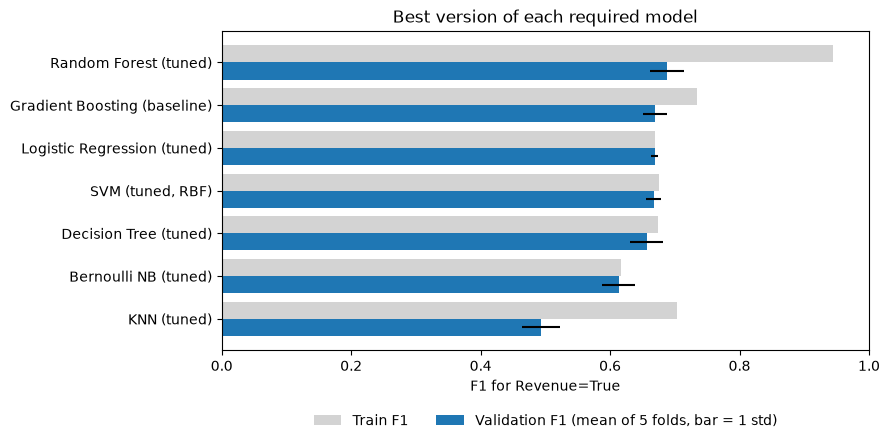

In [27]:
plot_data = best_per_model.iloc[::-1]
positions = np.arange(len(plot_data))

fig, ax = plt.subplots(figsize=(9, 4.6))
ax.barh(positions + 0.2, plot_data["Train F1"], height=0.4,
        color="lightgray", label="Train F1")
ax.barh(positions - 0.2, plot_data["Val F1"], height=0.4, xerr=plot_data["Val F1 std"],
        color="tab:blue", label="Validation F1 (mean of 5 folds, bar = 1 std)")
ax.set_yticks(positions, plot_data["Model"])
ax.set_xlabel("F1 for Revenue=True")
ax.set_xlim(0, 1)
ax.set_title("Best version of each required model")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=2, frameon=False)
plt.tight_layout()
plt.show()

**Key points:**

- **The tuned Random Forest has the highest validation F1 (0.688).** Gradient Boosting (0.670), tuned Logistic
  Regression (0.669) and tuned SVM (0.667) follow and are effectively tied: the differences between them are far
  smaller than the fold-to-fold variation. The tuned Decision Tree (0.657) is close behind.
- **Handling the class imbalance was the biggest improvement.** `class_weight="balanced"` raised Logistic Regression
  from 0.515 to 0.669 (recall 0.394 to 0.716). `class_weight="balanced_subsample"` together with `min_samples_leaf=2`
  raised the Random Forest from 0.634 to 0.688 (recall 0.537 to 0.695).
- **Grid Search helped most where the baseline did not suit this data.** Besides Logistic Regression and Random
  Forest this is the Decision Tree: limiting it to depth 4 with at least 10 sessions per leaf raised its F1 from
  0.572 to 0.657. Naive Bayes, KNN and SVM gained 0.02 or less. For Gradient Boosting the grid of 32 configurations
  selected the default settings, so its tuned and baseline versions are the same model (0.670).
- **`PageValues` carries most of the F1 signal.** The tuned L1 Logistic Regression keeps only this one feature
  (1 of 75) and still matches SVM and Gradient Boosting on F1. The ensembles use the other features to rank the
  sessions better: ROC AUC is 0.930 for the Random Forest and 0.932 for Gradient Boosting, against 0.870 for the
  tuned Logistic Regression.
- **Precision and recall:** SVM and Naive Bayes favor recall (0.69 to 0.77) with lower precision (0.55 to 0.59),
  Gradient Boosting and the tuned Decision Tree favor precision (about 0.73 against recall of 0.60 to 0.62), and the
  tuned Random Forest is the most balanced (0.682 and 0.695), which is what F1 rewards.

**Overfitting and underfitting:**

- **Underfitting:** baseline Logistic Regression (train 0.525, validation 0.515), which tuning fixed. The Naive Bayes
  models are stable but low on both training and validation data (about 0.60 to 0.62), which points to the
  independence assumption being too simple for this data.
- **Good fit:** tuned Logistic Regression, tuned SVM, the tuned Decision Tree and Gradient Boosting have small
  train-validation gaps (0.000, 0.008, 0.018 and 0.064) together with high validation F1.
- **Overfitting:** the unpruned baseline Decision Tree (train 1.000, validation 0.572), which Grid Search fixed by
  limiting the depth and the leaf size. KNN stays overfitted: tuning to `K=3` raised F1 slightly but widened the gap
  from 0.126 to 0.210, because a small K memorizes the training data.
- **Random Forest:** the gap stays large after tuning (0.944 against 0.688), which is typical for a forest of deep
  trees. Larger leaves reduced the gap from 0.366 to 0.255 and raised the validation F1 at the same time.

## 7. Final model selection

In [28]:
FINAL_MODEL = "Random Forest (tuned)"

candidates = best_per_model["Model"].tolist()

per_fold = pd.DataFrame(
    {name: fold_f1[name] for name in candidates},
    index=[f"Fold {fold}" for fold in range(1, len(cv) + 1)],
)
per_fold.loc["Mean"] = per_fold.mean()
display(per_fold.round(3))

difference = pd.DataFrame({
    name: fold_f1[FINAL_MODEL] - fold_f1[name]
    for name in candidates if name != FINAL_MODEL
})
paired = pd.DataFrame({
    "Mean F1 difference": difference.mean(),
    "Smallest difference": difference.min(),
    "Folds where the final model is better": (difference > 0).sum(),
})
print(f"{FINAL_MODEL} compared with the best version of every other model, fold by fold:")
display(paired.round(3))

,Random Forest (tuned),Gradient Boosting (baseline),Logistic Regression (tuned),"SVM (tuned, RBF)",Decision Tree (tuned),Bernoulli NB (tuned),KNN (tuned)
Fold 1,0.703,0.682,0.670,0.675,0.679,0.636,0.481
Fold 2,0.715,0.682,0.670,0.679,0.655,0.651,0.550
Fold 3,0.653,0.650,0.661,0.659,0.618,0.586,0.475
Fold 4,0.660,0.645,0.664,0.648,0.643,0.592,0.471
Fold 5,0.711,0.689,0.678,0.676,0.689,0.603,0.487
Mean,0.688,0.670,0.669,0.667,0.657,0.614,0.493


Random Forest (tuned) compared with the best version of every other model, fold by fold:


,Mean F1 difference,Smallest difference,Folds where the final model is better
Gradient Boosting (baseline),0.019,0.002,5
Logistic Regression (tuned),0.020,-0.009,3
"SVM (tuned, RBF)",0.021,-0.006,4
Decision Tree (tuned),0.031,0.017,5
Bernoulli NB (tuned),0.075,0.064,5
KNN (tuned),0.195,0.165,5


In [29]:
final_params = estimators[FINAL_MODEL].named_steps["clf"].get_params()
print(FINAL_MODEL)
for key in ["n_estimators", "max_depth", "min_samples_leaf", "max_features", "class_weight"]:
    print(f"  {key}: {final_params[key]}")

Random Forest (tuned)
  n_estimators: 400
  max_depth: None
  min_samples_leaf: 2
  max_features: sqrt
  class_weight: balanced_subsample


**Final model: the tuned Random Forest** in the shared preprocessing pipeline (`n_estimators=400`,
`min_samples_leaf=2`, `max_features="sqrt"`, `class_weight="balanced_subsample"`, no depth limit).

We expect it to generalize best to unseen sessions, for the following reasons:

- **Validation performance.** It has the highest validation F1 for `Revenue=True` (0.688, against 0.667 to 0.670 for
  the next three models). It is better than Gradient Boosting in all five folds, better than the tuned SVM in four
  and better than the tuned Logistic Regression in three. The margin of about 0.02 is similar to the fold-to-fold
  standard deviation (0.027), so the advantage is moderate and not decisive. The threshold-independent metrics
  support it: average precision is 0.743 and ROC AUC is 0.930, clearly above Logistic Regression (0.637 and 0.870)
  and SVM (0.688 and 0.914) and level with Gradient Boosting (0.746 and 0.932). So the forest ranks sessions as well
  as Gradient Boosting, and with class weighting its decisions are better balanced between precision and recall.
- **Overfitting.** The training F1 (0.944) is much higher than the validation F1, but this is expected for a Random
  Forest: every deep tree fits its bootstrap sample closely, and averaging 400 trees removes most of that variance.
  The validation F1, not the training F1, is our estimate of generalization, and tuning moved the model toward
  less overfitting (gap 0.366 to 0.255) while the validation F1 increased.
- **Model complexity.** More complex than Logistic Regression, but still one standard scikit-learn estimator,
  with no extra feature engineering or stacking.
- **Computational requirements.** One fit takes a few seconds on a laptop and the whole Grid Search took less than
  a minute, so cost is not a constraint for this dataset.
- **Interpretability.** Lower than for Logistic Regression, which here is practically a threshold on `PageValues`.
  The forest only offers feature importances (Section 9). We accept this because the goal is the best F1.

**Alternative considered:** the tuned Logistic Regression is the simplest and most stable candidate (standard
deviation 0.006, no train-validation gap). It would be the choice if interpretability mattered more than F1, but it
is 0.02 lower on validation F1 and much weaker at ranking sessions. The tuned Decision Tree (0.657) is another
readable alternative, 0.03 below the forest.

**Caveat:** the Random Forest settings were chosen among 16 grid configurations on the same folds that produce the
0.688, so this score is slightly optimistic and the F1 on the hidden test labels will probably be a little lower.
The same holds for the other tuned models, so the comparison between them remains fair.

## 8. Confusion matrix on the validation predictions

The validation predictions are out-of-fold: every training session is predicted by the model that was fitted on
the other four folds, so no prediction comes from a model that has seen that session.

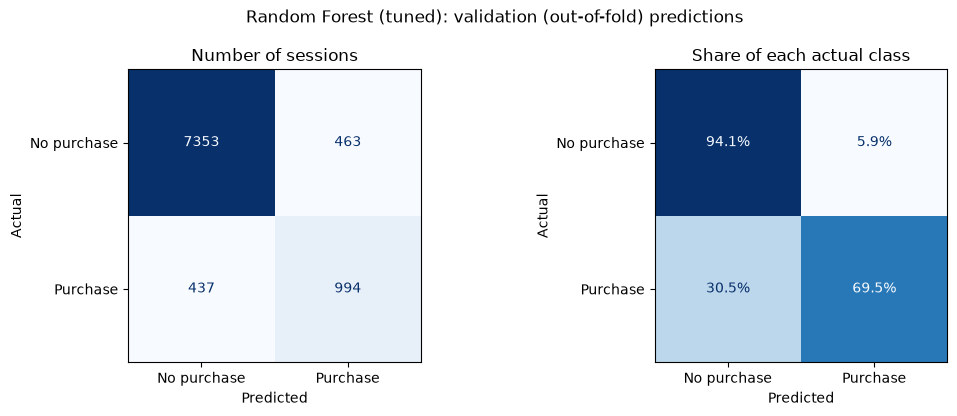

In [30]:
oof_pred = cross_val_predict(clone(estimators[FINAL_MODEL]), X, y, cv=cv, n_jobs=-1)

cm = confusion_matrix(y, oof_pred, labels=[False, True])
class_labels = ["No purchase", "Purchase"]

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
ConfusionMatrixDisplay(cm, display_labels=class_labels).plot(
    ax=axes[0], cmap="Blues", colorbar=False, values_format="d")
axes[0].set_title("Number of sessions")
ConfusionMatrixDisplay(cm / cm.sum(axis=1, keepdims=True), display_labels=class_labels).plot(
    ax=axes[1], cmap="Blues", colorbar=False, values_format=".1%")
axes[1].set_title("Share of each actual class")
for ax in axes:
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
fig.suptitle(f"{FINAL_MODEL}: validation (out-of-fold) predictions")
plt.tight_layout()
plt.show()

In [31]:
tn, fp, fn, tp = cm.ravel()
print(f"True negatives: {tn} | False positives: {fp} | False negatives: {fn} | True positives: {tp}\n")
print(classification_report(y, oof_pred, target_names=class_labels, digits=3))

print(f"F1 for Revenue=True, mean of the five folds: "
      f"{fold_f1[FINAL_MODEL].mean():.4f} (std {fold_f1[FINAL_MODEL].std():.4f})")
print(f"F1 for Revenue=True, all out-of-fold predictions together: "
      f"{f1_score(y, oof_pred, pos_label=True):.4f}")
print(f"Accuracy: {accuracy_score(y, oof_pred):.4f} "
      f"(always predicting 'no purchase': {1 - y.mean():.4f}, with F1 = 0)")

True negatives: 7353 | False positives: 463 | False negatives: 437 | True positives: 994

              precision    recall  f1-score   support

 No purchase      0.944     0.941     0.942      7816
    Purchase      0.682     0.695     0.688      1431

    accuracy                          0.903      9247
   macro avg      0.813     0.818     0.815      9247
weighted avg      0.903     0.903     0.903      9247

F1 for Revenue=True, mean of the five folds: 0.6884 (std 0.0266)
F1 for Revenue=True, all out-of-fold predictions together: 0.6884
Accuracy: 0.9027 (always predicting 'no purchase': 0.8452, with F1 = 0)


**Final validation performance: F1 = 0.688 for `Revenue=True`** (precision 0.682, recall 0.695).

Reading the confusion matrix:

- **Purchases found:** 994 of the 1,431 actual purchases are predicted correctly (recall 69.5%), 437 are missed.
- **False alarms:** 463 sessions without a purchase are predicted as purchases. Of the 1,457 sessions predicted as
  a purchase, 994 are real (precision 68.2%).
- **The two kinds of error are balanced** (463 false positives, 437 false negatives). This is why precision and
  recall are almost equal: the model does not buy one at the expense of the other.
- **No-purchase sessions:** 94.1% are recognized correctly.
- **Why accuracy alone would mislead:** accuracy is 0.903, which looks strong, but always predicting "no purchase"
  already gives 0.845 without finding a single buyer. The model still misses 3 of every 10 purchases, and only F1,
  precision and recall for the positive class show that.

## 9. Final training and test predictions

The final model is refitted on **all 9,247 training sessions** with the hyperparameters selected above.
The preprocessing is part of the pipeline, so it is refitted on the same rows. Only now is the test file read,
and it is used for nothing except generating the predictions.

In [32]:
final_model = clone(estimators[FINAL_MODEL]).fit(X, y)

test_df = pd.read_csv("challenge2_test.csv")
X_test = test_df[X.columns]  # same predictors in the same order as in training; ID is not used

predictions = pd.DataFrame({
    "ID": test_df["ID"],
    "Revenue": final_model.predict(X_test),
})
predictions.to_csv("predictions.csv", index=False)

print("Saved predictions.csv:", predictions.shape)
predictions.head()

Saved predictions.csv: (3083, 2)


,ID,Revenue
0,2,False
1,5,False
2,6,False
3,8,False
4,10,False


In [33]:
# Checks on the submission file
saved = pd.read_csv("predictions.csv")

assert saved.columns.tolist() == ["ID", "Revenue"]
assert len(saved) == len(test_df) == 3083
assert saved["ID"].is_unique and saved["ID"].equals(test_df["ID"])
assert saved["Revenue"].dtype == bool and saved["Revenue"].notna().all()

print("Rows:", len(saved), "| unique IDs:", saved["ID"].nunique())
print("Predicted purchases:", int(saved["Revenue"].sum()),
      f"({100 * saved['Revenue'].mean():.2f}% of the test sessions)")
print(f"Purchase rate in the training data: {100 * y.mean():.2f}%")
print(f"Share predicted as purchase on validation: {100 * oof_pred.mean():.2f}%")

Rows: 3083 | unique IDs: 3083
Predicted purchases: 444 (14.40% of the test sessions)
Purchase rate in the training data: 15.48%
Share predicted as purchase on validation: 15.76%


### What the final model relies on

Impurity-based feature importances of the final Random Forest. The importances of the one-hot columns are summed
back to their original feature.

In [34]:
def original_feature(column):
    name = column.split("__", 1)[1]
    return next((c for c in categorical_features if name.startswith(c + "_")), name)

importances = pd.Series(
    final_model.named_steps["clf"].feature_importances_,
    index=final_model.named_steps["preprocess"].get_feature_names_out(),
)
importances = importances.groupby(original_feature).sum().sort_values(ascending=False)
importances.to_frame("Importance").round(3)

,Importance
PageValues,0.377
ExitRates,0.090
ProductRelated_Duration,0.079
ProductRelated,0.071
Month,0.064
BounceRates,0.055
Administrative_Duration,0.045
TrafficType,0.042
Administrative,0.039
Region,0.033


`PageValues` alone accounts for 38% of the importance, far ahead of `ExitRates`, `ProductRelated_Duration`,
`ProductRelated` and `Month`. This agrees with the exploration in Section 1 and with the L1 Logistic Regression that
kept only `PageValues`. Impurity-based importances favor numeric features with many distinct values, so the order
of the lower-ranked features should not be over-interpreted.

## 10. Summary

- **Data:** 9,247 training sessions, 15.48% with a purchase, no missing values. `ID` is not used as a predictor.
- **Validation:** five stratified group folds shared by all models, with preprocessing fitted inside each fold.
  F1 for `Revenue=True` is the primary metric.
- **Models:** all seven required models were evaluated as baselines and tuned with Grid Search (Section 6).
- **Final model:** tuned Random Forest, validation F1 = 0.688 for `Revenue=True` (precision 0.682, recall 0.695).
- **Predictions:** `predictions.csv` contains `ID` and `Revenue` (`True` or `False`) for all 3,083 test sessions.
  The test file was used only to generate these predictions.